Daily Crime Count Forecasting
Goal: predict future daily crime counts using historical crime activity and temporal features.

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [47]:
df = pd.read_csv("../data/crimes_features.csv")

df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce'
)

print("Shape:", df.shape)
print("Start:", df['date'].min())
print("End:", df['date'].max())

Shape: (1388164, 27)
Start: 2021-01-01 00:00:00
End: 2026-10-03 00:00:00


In [48]:
daily = (
    df
    .set_index('date')
    .resample('D')
    .size()
    .rename('crime_count')
    .to_frame()
)

print(daily.shape)
daily.head()

(2102, 1)


,crime_count
date,
2021-01-01,882
2021-01-02,450
2021-01-03,516
2021-01-04,536
2021-01-05,543


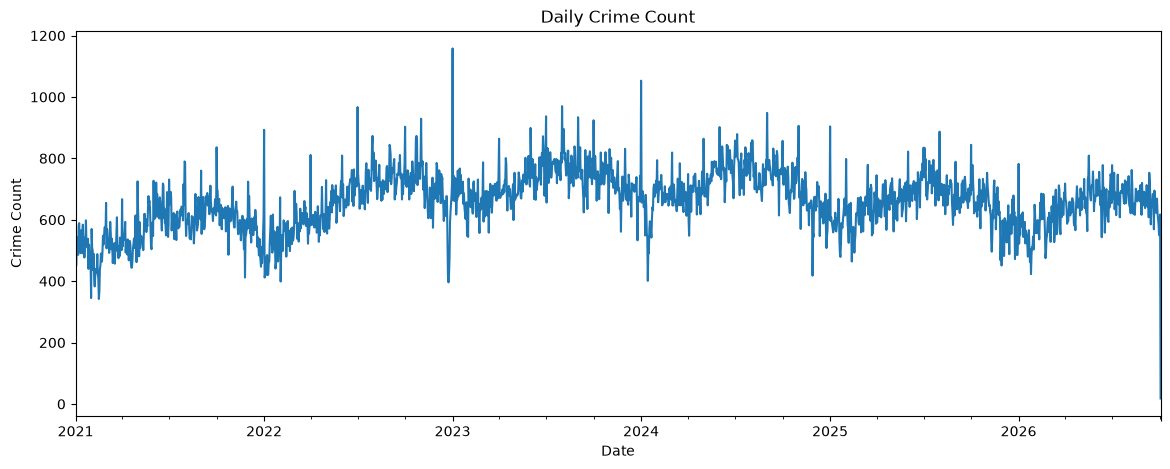

In [49]:
daily['crime_count'].plot(
    figsize=(14, 5),
    title='Daily Crime Count'
)

plt.xlabel('Date')
plt.ylabel('Crime Count')
plt.show()

In [50]:
daily['day_of_week'] = daily.index.dayofweek
daily['month'] = daily.index.month
daily['year'] = daily.index.year

daily['day_sin'] = np.sin(
    2 * np.pi * daily['day_of_week'] / 7
)

daily['day_cos'] = np.cos(
    2 * np.pi * daily['day_of_week'] / 7
)

daily['month_sin'] = np.sin(
    2 * np.pi * (daily['month'] - 1) / 12
)

daily['month_cos'] = np.cos(
    2 * np.pi * (daily['month'] - 1) / 12
)

In [51]:
daily['lag_1'] = daily['crime_count'].shift(1)
daily['lag_7'] = daily['crime_count'].shift(7)
daily['lag_14'] = daily['crime_count'].shift(14)
daily['lag_28'] = daily['crime_count'].shift(28)

In [52]:
daily['rolling_7_mean'] = (
    daily['crime_count']
    .shift(1)
    .rolling(7)
    .mean()
)

daily['rolling_28_mean'] = (
    daily['crime_count']
    .shift(1)
    .rolling(28)
    .mean()
)

daily['rolling_7_std'] = (
    daily['crime_count']
    .shift(1)
    .rolling(7)
    .std()
)

In [53]:
daily = daily.dropna().copy()

print("Forecast dataset:", daily.shape)

daily.head()

Forecast dataset: (2074, 15)


,crime_count,day_of_week,month,year,day_sin,day_cos,month_sin,month_cos,lag_1,lag_7,lag_14,lag_28,rolling_7_mean,rolling_28_mean,rolling_7_std
date,,,,,,,,,,,,,,,
2021-01-29,494,4,1,2021,-0.433884,-0.900969,0.0,1.000000,481.0,521.0,584.0,882.0,505.142857,537.285714,33.879338
2021-01-30,464,5,1,2021,-0.974928,-0.222521,0.0,1.000000,494.0,528.0,489.0,450.0,501.285714,523.428571,33.305226
2021-01-31,345,6,1,2021,-0.781831,0.623490,0.0,1.000000,464.0,509.0,542.0,516.0,492.142857,523.928571,33.533210
2021-02-01,570,0,2,2021,0.000000,1.000000,0.5,0.866025,345.0,538.0,477.0,536.0,468.714286,517.821429,63.602186
2021-02-02,508,1,2,2021,0.781831,0.623490,0.5,0.866025,570.0,440.0,522.0,543.0,473.285714,519.035714,70.218028


In [54]:
features = [
    'day_of_week',
    'month',
    'year',
    'day_sin',
    'day_cos',
    'month_sin',
    'month_cos',
    'lag_1',
    'lag_7',
    'lag_14',
    'lag_28',
    'rolling_7_mean',
    'rolling_28_mean',
    'rolling_7_std'
]

X = daily[features]
y = daily['crime_count']

print("X:", X.shape)
print("y:", y.shape)

X: (2074, 14)
y: (2074,)


In [55]:
split_index = int(len(daily) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print()
print("Train period:")
print(X_train.index.min(), "â†’", X_train.index.max())

print()
print("Test period:")
print(X_test.index.min(), "â†’", X_test.index.max())

Train: (1659, 14)
Test: (415, 14)

Train period:
2021-01-29 00:00:00 â†’ 2025-08-14 00:00:00

Test period:
2025-08-15 00:00:00 â†’ 2026-10-03 00:00:00


In [56]:
model = HistGradientBoostingRegressor(
    loss='poisson',
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained âœ…")

Model trained âœ…


In [57]:
y_pred = model.predict(X_test)

y_pred = np.maximum(y_pred, 0)

print(y_pred[:10])

[707.85189047 725.64051994 678.68738232 672.66423933 716.53080863
 673.09118288 681.9812318  711.48531302 717.56615277 722.83066315]


In [58]:
mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("MODEL PERFORMANCE")
print("-----------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"RÂ²   : {r2:.4f}")

MODEL PERFORMANCE
-----------------
MAE  : 40.67
RMSE : 58.88
RÂ²   : 0.3701


In [59]:
baseline_pred = X_test['lag_7'].values

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_pred
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_pred
)

print("BASELINE PERFORMANCE")
print("--------------------")
print(f"MAE  : {baseline_mae:.2f}")
print(f"RMSE : {baseline_rmse:.2f}")
print(f"RÂ²   : {baseline_r2:.4f}")

BASELINE PERFORMANCE
--------------------
MAE  : 56.75
RMSE : 78.14
RÂ²   : -0.1094


In [60]:
comparison = pd.DataFrame({
    'Model': [
        'Baseline Lag 7',
        'HistGradientBoosting'
    ],
    'MAE': [
        baseline_mae,
        mae
    ],
    'RMSE': [
        baseline_rmse,
        rmse
    ],
    'R2': [
        baseline_r2,
        r2
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Baseline Lag 7,56.749398,78.142517,-0.109446
1,HistGradientBoosting,40.673713,58.879326,0.370121


In [61]:
results = pd.DataFrame({
    'actual': y_test,
    'predicted': y_pred,
    'baseline': baseline_pred
})

results.head(20)

,actual,predicted,baseline
date,,,
2025-08-15,745,707.851890,646.0
2025-08-16,647,725.640520,669.0
2025-08-17,652,678.687382,714.0
2025-08-18,694,672.664239,683.0
2025-08-19,684,716.530809,618.0
2025-08-20,712,673.091183,685.0
2025-08-21,707,681.981232,689.0
2025-08-22,730,711.485313,745.0
2025-08-23,717,717.566153,647.0


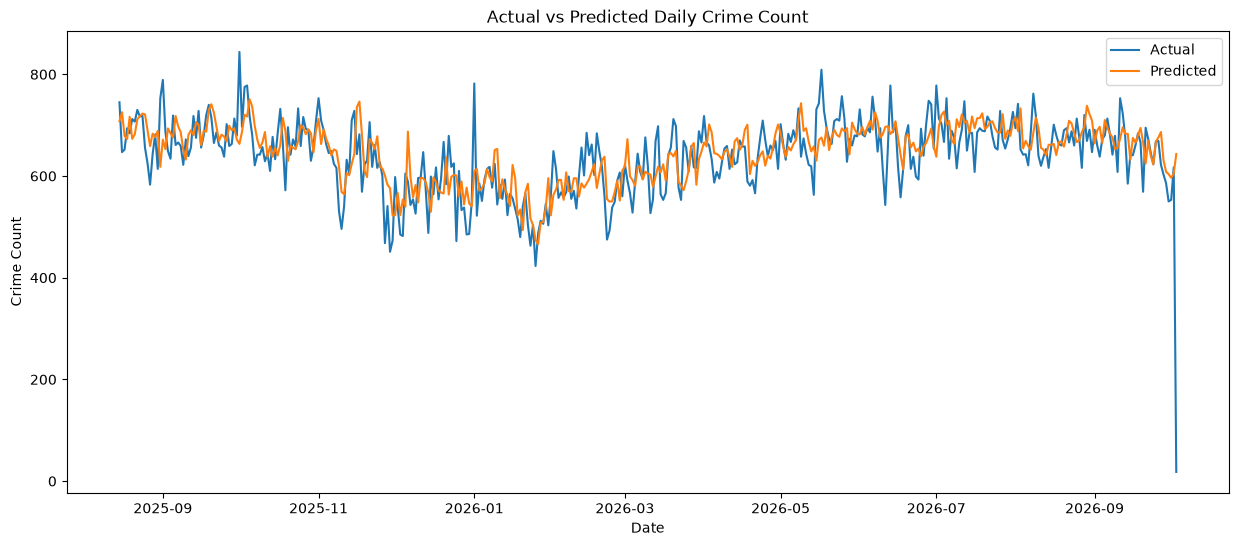

In [62]:
plt.figure(figsize=(15, 6))

plt.plot(
    results.index,
    results['actual'],
    label='Actual',
    linewidth=1.5
)

plt.plot(
    results.index,
    results['predicted'],
    label='Predicted',
    linewidth=1.5
)

plt.title(
    'Actual vs Predicted Daily Crime Count'
)

plt.xlabel('Date')
plt.ylabel('Crime Count')

plt.legend()
plt.show()

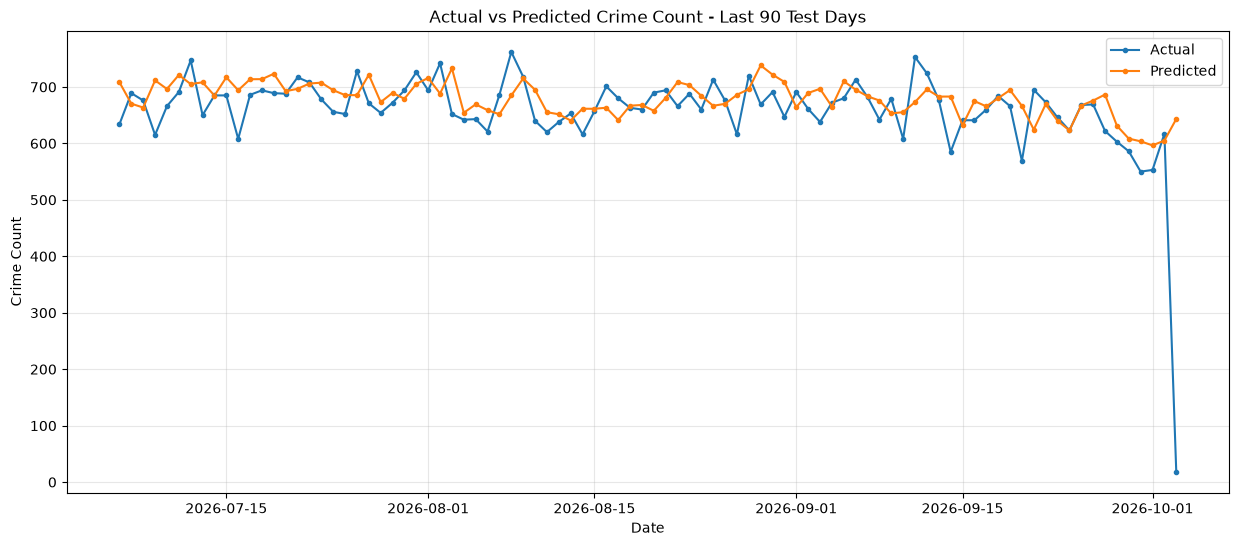

In [63]:
last_90 = results.tail(90)

plt.figure(figsize=(15, 6))

plt.plot(
    last_90.index,
    last_90['actual'],
    label='Actual',
    marker='o',
    markersize=3
)

plt.plot(
    last_90.index,
    last_90['predicted'],
    label='Predicted',
    marker='o',
    markersize=3
)

plt.title(
    'Actual vs Predicted Crime Count - Last 90 Test Days'
)

plt.xlabel('Date')
plt.ylabel('Crime Count')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [64]:
results['error'] = (
    results['actual']
    - results['predicted']
)

results['absolute_error'] = (
    results['error'].abs()
)

results.head()

,actual,predicted,baseline,error,absolute_error
date,,,,,
2025-08-15,745,707.851890,646.0,37.148110,37.148110
2025-08-16,647,725.640520,669.0,-78.640520,78.640520
2025-08-17,652,678.687382,714.0,-26.687382,26.687382
2025-08-18,694,672.664239,683.0,21.335761,21.335761
2025-08-19,684,716.530809,618.0,-32.530809,32.530809


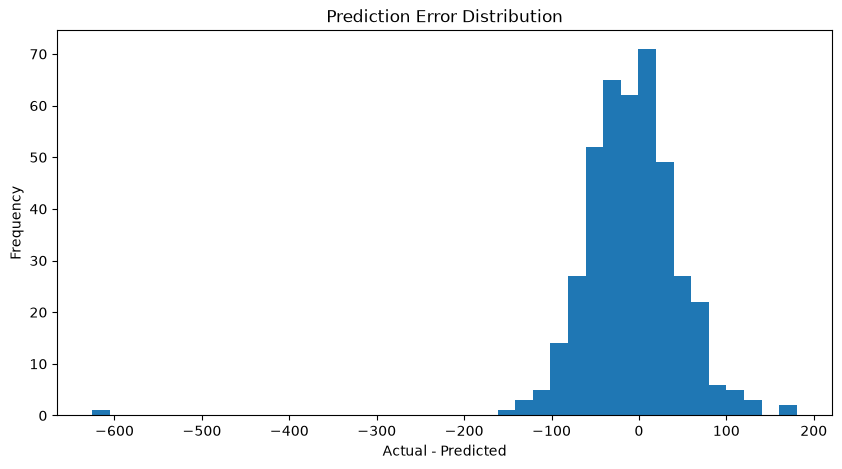

In [65]:
plt.figure(figsize=(10, 5))

plt.hist(
    results['error'],
    bins=40
)

plt.title('Prediction Error Distribution')

plt.xlabel('Actual - Predicted')
plt.ylabel('Frequency')

plt.show()

In [66]:
print(
    "Average error:",
    round(
        results['error'].mean(),
        2
    )
)

print(
    "Average absolute error:",
    round(
        results['absolute_error'].mean(),
        2
    )
)

Average error: -8.17
Average absolute error: 40.67


In [67]:
results.to_csv(
    "../data/daily_crime_predictions.csv"
)

print("Predictions saved âœ…")

Predictions saved âœ…


In [68]:
from sklearn.model_selection import TimeSeriesSplit

In [69]:
tscv = TimeSeriesSplit(
    n_splits=5
)

fold_results = []

In [70]:
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X),
    start=1
):

    X_train_cv = X.iloc[train_idx]
    X_val_cv = X.iloc[val_idx]

    y_train_cv = y.iloc[train_idx]
    y_val_cv = y.iloc[val_idx]

    model_cv = HistGradientBoostingRegressor(
        loss='poisson',
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=31,
        random_state=42
    )

    model_cv.fit(
        X_train_cv,
        y_train_cv
    )

    pred_cv = model_cv.predict(
        X_val_cv
    )

    pred_cv = np.maximum(
        pred_cv,
        0
    )

    mae_cv = mean_absolute_error(
        y_val_cv,
        pred_cv
    )

    rmse_cv = np.sqrt(
        mean_squared_error(
            y_val_cv,
            pred_cv
        )
    )

    r2_cv = r2_score(
        y_val_cv,
        pred_cv
    )

    fold_results.append({
        'fold': fold,
        'MAE': mae_cv,
        'RMSE': rmse_cv,
        'R2': r2_cv
    })

In [71]:
cv_results = pd.DataFrame(
    fold_results
)

cv_results

,fold,MAE,RMSE,R2
0,1,64.663238,80.803811,0.180256
1,2,48.245280,69.460448,0.154042
2,3,39.757295,54.226576,0.425598
3,4,44.715853,59.334289,0.213560
4,5,41.449156,60.811545,0.358564


In [72]:

print("TIME SERIES CV")
print("----------------")

print(
    f"Average MAE: "
    f"{cv_results['MAE'].mean():.2f}"
)

print(
    f"Average RMSE: "
    f"{cv_results['RMSE'].mean():.2f}"
)

print(
    f"Average RÂ²: "
    f"{cv_results['R2'].mean():.4f}"
)

print()

print(
    "RÂ² standard deviation:",
    round(
        cv_results['R2'].std(),
        4
    )
)

TIME SERIES CV
----------------
Average MAE: 47.77
Average RMSE: 64.93
Average RÂ²: 0.2664

RÂ² standard deviation: 0.119


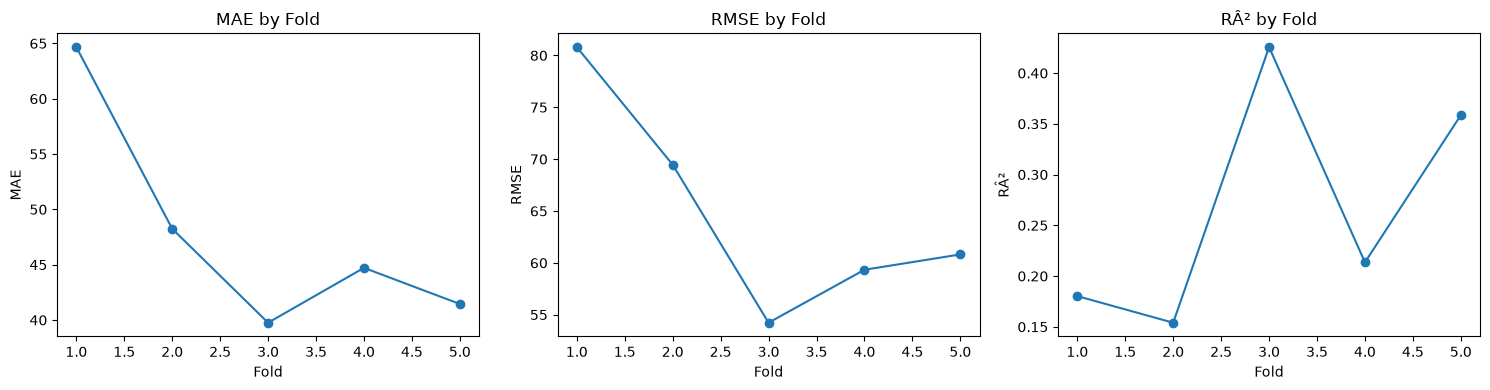

In [73]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)

axes[0].plot(
    cv_results['fold'],
    cv_results['MAE'],
    marker='o'
)

axes[0].set_title('MAE by Fold')
axes[0].set_xlabel('Fold')
axes[0].set_ylabel('MAE')


axes[1].plot(
    cv_results['fold'],
    cv_results['RMSE'],
    marker='o'
)

axes[1].set_title('RMSE by Fold')
axes[1].set_xlabel('Fold')
axes[1].set_ylabel('RMSE')


axes[2].plot(
    cv_results['fold'],
    cv_results['R2'],
    marker='o'
)

axes[2].set_title('RÂ² by Fold')
axes[2].set_xlabel('Fold')
axes[2].set_ylabel('RÂ²')

plt.tight_layout()
plt.show()

In [74]:
experiment_summary = pd.DataFrame({
    'version': [
        'V1',
        'V2_Model_D'
    ],
    'MAE': [
        47.77,
        49.974532
    ],
    'RMSE': [
        64.93,
        66.665106
    ],
    'R2': [
        0.2664,
        0.221359
    ],
    'R2_std': [
        0.1190,
        0.213080
    ]
})

experiment_summary

,version,MAE,RMSE,R2,R2_std
0,V1,47.770000,64.930000,0.266400,0.11900
1,V2_Model_D,49.974532,66.665106,0.221359,0.21308


In [75]:
X_final = X.copy()
y_final = y.copy()

print(X_final.shape)
print(y_final.shape)

(2074, 14)
(2074,)


In [76]:
final_model = HistGradientBoostingRegressor(
    loss='poisson',
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    random_state=42
)

final_model.fit(
    X_final,
    y_final
)

print("Final forecasting model trained âœ…")

Final forecasting model trained âœ…


In [ ]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model,
    "../models/crime_forecast_model.joblib"
)

print("Model saved âœ…")

In [ ]:
joblib.dump(
    features,
    "../models/crime_forecast_features.joblib"
)

print("Features saved âœ…")

In [ ]:
daily.to_csv(
    "../data/daily_crime_series.csv"
)

print("Daily crime series saved âœ…")

In [80]:
print(
    os.path.exists(
        "../models/crime_forecast_model.joblib"
    )
)

print(
    os.path.exists(
        "../models/crime_forecast_features.joblib"
    )
)

print(
    os.path.exists(
        "../data/daily_crime_series.csv"
    )
)

True
True
True


### Expérience V2

Des variables retardées et fenêtres glissantes supplémentaires ont été testées, mais elles n'ont pas amélioré les performances en validation temporelle.

Le modèle final conserve donc la configuration V1.